# Causal analysis of success: talent, luck, and capital

- This notebook runs one baseline experiment of the talent and luck simulation
  (100 agents, 80 periods, seed 42) and analyzes it end to end
  - The building blocks of the simulation are in `causal_success_API.ipynb`
  - The set-up and the notation are in `README.md`
- The pedagogical arc:
  - The baseline: one config, one run, the talents and the final capital
  - Associations: how talent and realized events line up with log-capital
  - Causal estimates: the effect of one realized beneficial event, with the
    uncertainty of the estimator
  - Policies: what allocating resources before the run changes
  - The paper: how the baseline compares with the reported numbers

In [1]:
%load_ext autoreload
%autoreload 2

import logging

import pandas as pd

In [2]:
import helpers.hintrospection as hintros
import helpers.hnotebook as hnotebook

import causal_success_utils as utils
import causal_success_analysis_utils as analysis

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

/opt/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO  > /opt/venv/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpi50onkmo.json --HistoryManager.hist_file=:memory:


# Part 1: The baseline experiment

## Cell 1.1: The config of the baseline

- `get_default_config()` returns every parameter of one experiment
  - Each value is the default of the simulation function that uses it
- Every result in this notebook comes from this config and from one call to
  `run_experiment()`

In [3]:
# Get the config of the baseline experiment and list its parameters.
config = utils.get_default_config()
display(analysis.cell1_1_config_to_df(config))
# Outcome: 22 parameters, e.g., 100 agents, 80 periods, seed 42, and no policy.

,group,parameter,value
0,experiment,seed,42
1,population,n_agents,100
2,population,talent_mean,0.5
3,population,talent_std,0.15
4,population,talent_clip,"(0.0, 1.0)"
5,population,initial_capital,1.0
6,events,n_periods,80
7,events,n_lucky_per_period,5
8,events,n_unlucky_per_period,5
9,events,lucky_mean,0.25


In [4]:
# Describe the set-up in one line, to show it on every plot.
setup_txt = analysis.cell1_1_get_setup_txt(config)
print("setup_txt=", setup_txt)
# Outcome: "100 agents, 80 periods, seed 42".

setup_txt= 100 agents, 80 periods, seed 42


## Cell 1.2: Running the baseline

In [5]:
# How one run works, with the values of the default config:
#
# - Each agent has 3 talents drawn from N(0.5, 0.15) and clipped to [0, 1], and
#   starts with capital 1.0
# - Each period has 5 lucky and 5 unlucky events
#   - Each event hits one agent, picked with probability proportional to a
#     sigmoid of its intensity
# - A lucky event multiplies the capital by (1 + impact) only if the agent
#   passes an IQ check, i.e., with probability `iq`
#   - The impact is drawn from N(0.25, 0.08) and clipped to [0.05, 0.5]
# - After every lucky event, with probability 0.1, a spillover can reach another
#   agent
#   - The check runs whether or not the hit agent capitalized on the event
#   - The recipient is drawn from all agents in proportion to networking: there
#     is no network graph
#   - If the draw picks the hit agent, there is no spillover
#   - The recipient must pass its own IQ check
#   - The spillover impact is half the impact of the lucky event
# - An unlucky event always applies: it multiplies the capital by
#   (1 - impact), with the impact drawn from N(0.15, 0.05) and clipped to
#   [0.05, 0.3]
# - `lucky_events` counts the realized beneficial events of an agent
#   - The direct events it capitalized on, plus the spillovers it received
#   - Not the lucky events it met without capitalizing on them
print("One run applies random events to the agents and compounds their capital")

One run applies random events to the agents and compounds their capital


In [6]:
# Run the baseline experiment once: every later cell uses `results`.
results = utils.run_experiment(config)
df = results["df"]
display(df.head())
# Outcome: one row per agent with its talents, final capital, and event counts.

,id,talent_intensity,talent_iq,talent_networking,initial_capital,talent_norm,capital,lucky_events,unlucky_events,net_events
0,0,0.545708,0.344002,0.612568,1.0,1.338422,0.508831,1,4,-3
1,1,0.641085,0.207345,0.304673,1.0,1.243707,0.488271,1,7,-6
2,2,0.519176,0.452564,0.497480,1.0,1.312190,0.795865,4,5,-1
3,3,0.372043,0.631910,0.616669,1.0,1.384921,0.977459,3,5,-2
4,4,0.509905,0.669086,0.570126,1.0,1.425736,0.400109,3,9,-6


In [7]:
# Show the summary statistics of the baseline.
display(pd.Series(results["stats"], name="baseline").to_frame())
# Outcome: mean capital 0.888, median 0.816, Gini 0.217, 2.32 realized
# beneficial events and 4.00 unlucky events per agent on average.

,baseline
n_agents,100.000000
mean_capital,0.888435
median_capital,0.816072
std_capital,0.365407
min_capital,0.330285
max_capital,2.573136
capital_range,7.790659
gini_coefficient,0.217086
top_10_pct_share,0.184120
top_20_pct_share,0.320693


- The median agent ends below its starting capital of 1.0
  - On average an agent realizes 2.32 beneficial events and suffers 4.00
    unlucky ones
  - A lucky event is realized only with probability `iq`, about 0.5 on
    average (Cell 1.3), while every unlucky event applies
- The richest agent holds 7.79 times the capital of the poorest one

## Cell 1.3: The talents of the agents

**Goal**
- Check that the talents are roughly symmetric around 0.5 before the run

**Description**
- Inputs
  - `df`: the results table of the baseline
  - `setup_txt`: the set-up shown in the title

- Panels
  - `Intensity`: histogram of the intensity, with its mean and std
  - `IQ`: histogram of the IQ, with its mean and std
  - `Networking`: histogram of the networking, with its mean and std

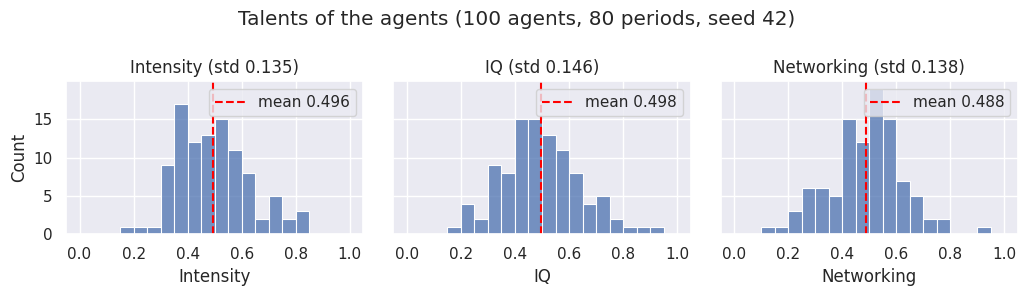

In [8]:
# Plot the distribution of each talent on the same axes.
analysis.cell1_3_plot_talent_distributions(df, setup_txt, figsize=(10.5, 3))

**Guided usage**
- Look at the 3 panels
  - Observe means near 0.5 and sample standard deviations around 0.14
  - These differ from the configured 0.15 because this is a finite sample
  - No talent draws were clipped in this baseline run
- Compare the ranges of the panels
  - Observe that most agents have talents between about 0.3 and 0.7, with a
    few agents in the tails

**Implementation** `cell1_3_plot_talent_distributions(df, setup_txt, ...)`
- Draws one `seaborn` histogram per talent, with the same bins on [0, 1]
- Marks the mean with a dashed line and writes the std in the title

In [9]:
hintros.print_obj_info(analysis.cell1_3_plot_talent_distributions)

- `cell1_3_plot_talent_distributions(df: pandas.DataFrame, setup_txt: str, *, figsize: Optional[Tuple[float, float]] = None) -> None`  
  Plot the distribution of each talent, on the same axes...

https://github.com/bkk8403/gpsaggese.github.io/blob/UmdTask707_CAASL_Rewrite_example_notebook/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_analysis_utils.py#L93


# Part 2: Inequality of the final capital

## Cell 2.1: The distribution of the final capital

**Goal**
- See how unequal the capital becomes when every agent starts from 1.0

**Description**
- Inputs
  - `df`: the results table of the baseline
  - `results["stats"]`: the Gini and the shares of the same run
  - `setup_txt`: the set-up shown in the title

- Panels
  - `Capital`: histogram of the final capital, with its mean and median
  - `log(capital)`: histogram of the log of the final capital, the outcome of
    Part 4
  - `Lorenz`: share of capital held by the poorest share of agents

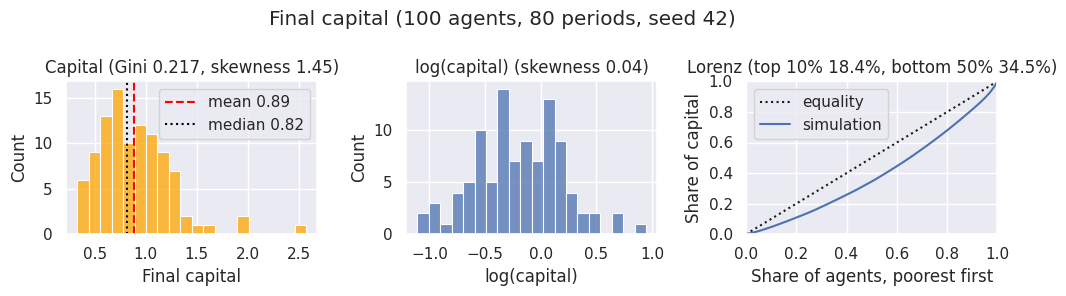

In [10]:
# Plot the final capital, its log, and its Lorenz curve.
analysis.cell2_1_plot_capital_distribution(
    df, results["stats"], setup_txt, figsize=(10.5, 3)
)

**Guided usage**
- Look at the `Capital` panel
  - Observe a right skew: the mean is above the median
- Look at the `log(capital)` panel
  - Observe a much smaller skew: the multiplicative events act additively on
    the log
- Look at the `Lorenz` panel
  - Observe a curve close to the diagonal: with a Gini of 0.217, the top 10%
    hold 18.4% of the capital and the bottom 50% hold 34.5%

**Implementation** `cell2_1_plot_capital_distribution(df, stats, setup_txt, ...)`
- Draws the histograms of the capital and of its log with `seaborn`
- Builds the Lorenz curve from the sorted capital
- Takes the Gini and the shares from `generate_summary_statistics()`, via
  `stats`

In [11]:
hintros.print_obj_info(analysis.cell2_1_plot_capital_distribution)

- `cell2_1_plot_capital_distribution(df: pandas.DataFrame, stats: Dict[str, float], setup_txt: str, *, figsize: Optional[Tuple[float, float]] = None) -> None`  
  Plot the final capital, its log, and its Lorenz curve...

https://github.com/bkk8403/gpsaggese.github.io/blob/UmdTask707_CAASL_Rewrite_example_notebook/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_analysis_utils.py#L137


- This baseline is moderately unequal, not heavy-tailed
  - A single run of 100 agents cannot show a power law
- Part 6 shows that seed 42 has the lowest Gini of 50 seeds

# Part 3: Talent, realized events, and log-capital

## Cell 3.1: What the event counts measure

In [12]:
# Event counts as predictors:
#
# - `lucky_events` is not pure luck: the talents change it
#   - Intensity raises the chance of being hit by any event
#   - IQ decides whether a lucky event is realized
#   - Networking and IQ decide who receives the spillovers
# - `unlucky_events` depends only on intensity and on chance
# - `net_events` is `lucky_events - unlucky_events`
# - The correlations below are associations: Part 4 adjusts for the talents
print("Realized events depend on talents, so their correlations are not causal")

Realized events depend on talents, so their correlations are not causal


## Cell 3.2: Correlations with log-capital

In [13]:
# Compute the correlation of each talent and event count with log-capital.
corr_df = analysis.cell3_2_compute_log_capital_correlations(df)
display(corr_df)
# Outcome: r = -0.045 for the talent norm, 0.540 for the realized beneficial
# events, and 0.920 for the net events.

,kind,r,ci_lower,ci_upper,p_value
predictor,,,,,
talent_norm,talent,-0.044716,-0.239035,0.153046,6.586645e-01
talent_intensity,talent,-0.041662,-0.236148,0.156033,6.806599e-01
talent_iq,talent,0.085599,-0.112714,0.277354,3.971148e-01
talent_networking,talent,-0.102760,-0.293259,0.095588,3.089750e-01
lucky_events,events,0.539700,0.383988,0.665564,6.861606e-09
unlucky_events,events,-0.596197,-0.709527,-0.452804,5.967841e-11
net_events,events,0.919901,0.883034,0.945484,1.256273e-41


- No talent has a correlation with log-capital that is distinguishable from 0
  in this run
  - The 95% interval of every talent contains 0, e.g., [-0.239, 0.153] for
    the talent norm
- The event counts are strongly associated with log-capital
  - Realized beneficial events: $r = 0.540$, 95% CI [0.384, 0.666]
  - Unlucky events: $r = -0.596$
  - Net events: $r = 0.920$, since each event adds or removes a similar
    amount of log-capital
- The ratio of the two correlations is not meaningful here: the talent
  correlation is negative and its interval contains 0

## Cell 3.3: Talent and realized events against log-capital

**Goal**
- See the weak talent association and the strong event association agent by
  agent

**Description**
- Inputs
  - `df`: the results table of the baseline
  - `corr_df`: the correlations of Cell 3.2, shown in the titles
  - `setup_txt`: the set-up shown in the title

- Panels
  - `Talent norm`: log-capital against the talent norm, with a linear fit
  - `Realized beneficial events`: log-capital against `lucky_events`, with a
    linear fit

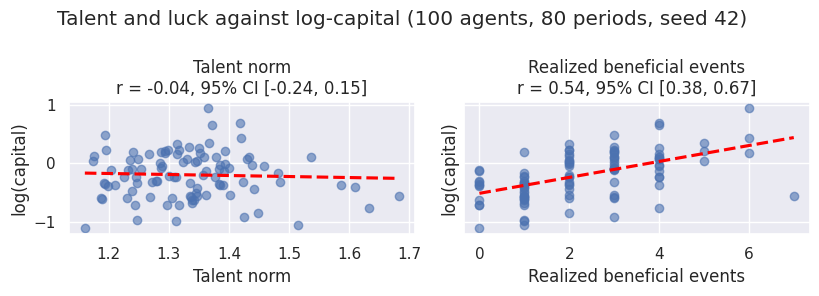

In [14]:
# Plot log-capital against the talent norm and the realized events.
analysis.cell3_3_plot_talent_and_luck_vs_log_capital(
    df, corr_df, setup_txt, figsize=(8.5, 3)
)

**Guided usage**
- Look at the `Talent norm` panel
  - Observe a flat fit: the talent norm does not sort the agents by capital
- Look at the `Realized beneficial events` panel
  - Observe the rising fit, and the vertical spread at each count: the
    unlucky events and the impact sizes also matter

**Implementation** `cell3_3_plot_talent_and_luck_vs_log_capital(df, corr_df, ...)`
- Draws a `seaborn` scatter with a linear fit per predictor, on a shared
  y-axis
- Writes the correlation and its interval from `corr_df` in each title

In [15]:
hintros.print_obj_info(analysis.cell3_3_plot_talent_and_luck_vs_log_capital)

- `cell3_3_plot_talent_and_luck_vs_log_capital(df: pandas.DataFrame, corr_df: pandas.DataFrame, setup_txt: str, *, figsize: Optional[Tuple[float, float]] = None) -> None`  
  Plot log-capital against the talent norm and against the lucky events...

https://github.com/bkk8403/gpsaggese.github.io/blob/UmdTask707_CAASL_Rewrite_example_notebook/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_analysis_utils.py#L260


## Cell 3.4: The richest agents

- `talent_rank` 1 is the agent with the highest talent norm
- `capital_rank` 1 is the agent with the highest final capital
- The two are separate rankings, usually of different agents
- A lower rank is better: the average rank of 100 agents is 50.5

In [16]:
# Rank the agents by talent and by capital.
df_ranked = analysis.cell3_4_add_ranks(df)
top_cols = [
    "id",
    "capital",
    "capital_rank",
    "talent_norm",
    "talent_rank",
    "lucky_events",
    "unlucky_events",
]
display(df_ranked.nsmallest(10, "capital_rank")[top_cols])
# Outcome: the 10 richest agents, with talent ranks from 17 to 94.

,id,capital,capital_rank,talent_norm,talent_rank,lucky_events,unlucky_events
6,6,2.573136,1.0,1.365554,33.0,6,1
51,51,1.986911,2.0,1.417705,18.0,4,1
26,26,1.929791,3.0,1.371717,31.0,4,1
76,76,1.618122,4.0,1.194075,94.0,3,0
39,39,1.549727,5.0,1.420095,17.0,6,3
52,52,1.411704,6.0,1.367399,32.0,5,4
8,8,1.405200,7.0,1.313800,56.0,2,1
66,66,1.321949,8.0,1.333611,51.0,3,1
64,64,1.299675,9.0,1.350784,39.0,4,3
24,24,1.261673,10.0,1.316457,55.0,3,3


## Cell 3.5: The richest agents against the others

In [17]:
# Compare the 10 richest agents with the other 90 and with all the agents.
n_top = 10
display(analysis.cell3_5_summarize_top_performers(df_ranked, n_top))
# Outcome: mean talent rank 42.6 for the top 10 against 51.4 for the others,
# and 4.0 against 2.1 realized beneficial events.

,n_agents,mean_talent_rank,median_talent_rank,mean_capital,mean_lucky_events,mean_unlucky_events,mean_net_events
group,,,,,,,
top,10,42.600000,36.0,1.635789,4.000000,1.800000,2.200000
others,90,51.377778,52.5,0.805395,2.133333,4.244444,-2.111111
all,100,50.500000,50.5,0.888435,2.320000,4.000000,-1.680000


- The 10 richest agents are slightly more talented than average in this run
  - Mean talent rank 42.6 and median 36.0, against 50.5 for the population
  - Lower is better, so they are not below-average talent
  - Their ranks still go from 17 to 94: the richest agents are not the most
    talented ones
- They realized more beneficial events and suffered fewer unlucky ones
  - 4.0 against 2.1 realized beneficial events
  - 1.8 against 4.2 unlucky events
  - Part of this is mechanical: selecting the richest agents selects the agents
    with the most realized gains
- 10 agents from one run are too few to separate talent from chance: Part 4
  estimates the effect of the events while adjusting for the talents

# Part 4: Causal effect of one realized beneficial event

## Cell 4.1: The causal set-up

In [18]:
# Causal set-up of Part 4:
#
# - Outcome Y_i: `log(capital)` of agent i at the end of the run
#   - The capital floor keeps the capital positive, so no `+ 1` shift is needed
# - Treatment D_i: `lucky_events`, the count of realized beneficial events,
#   including spillovers
# - Controls X_i: intensity, IQ, and networking
#   - They change both D_i (exposure, IQ check, spillovers) and Y_i
# - Estimand: the average change of Y_i for one more realized beneficial event,
#   holding the talents fixed
# - Assumptions that make the estimate causal:
#   - Given the talents, the rest of the variation of D_i comes from the random
#     draws of the simulator, independent of the unlucky events and of the
#     impact sizes
#   - Each event adds log(1 + impact) to Y_i, so the effect is additive in the
#     count
#   - Direct events and spillovers (half the impact) are pooled in one count, so
#     the estimand is an average over that mix
# - A confidence interval measures the sampling noise of the estimator under
#   these assumptions: it does not show that the assumptions hold
print("Y_i = log(capital), D_i = realized beneficial events, X_i = talents")

Y_i = log(capital), D_i = realized beneficial events, X_i = talents


## Cell 4.2: Observed log-capital change of each event

- In a simulation the log-capital change of each realized event is observed
  - Each event adds one entry to the capital history of the agent
  - Its change is the log of the ratio of 2 consecutive entries
- The kind of an event is read from the sign of its change
  - `unchanged` counts the events with no change, e.g., an unlucky event on
    an agent already at the capital floor
  - The floor can also make a detrimental change smaller than its impact
  - A kind with no event has undefined statistics (NaN)

In [19]:
# Measure the log-capital change of every realized event of the baseline.
display(analysis.cell4_2_compute_log_change_per_event(results["agents"]))
# Outcome: 232 beneficial events with a mean change of 0.199, 400 detrimental
# events with a mean change of -0.164, and no unchanged event.

,n_events,mean_log_change,std_log_change,min_log_change,max_log_change
event_kind,,,,,
beneficial,232,0.199352,0.072417,0.034333,0.373322
detrimental,400,-0.164393,0.056270,-0.316110,-0.051293
unchanged,0,NaN,NaN,NaN,NaN


- The observed average event-level log gain is 0.199 in this run
  - The changes go from 0.034 to 0.373, since the impacts are random and the
    spillovers have half the impact
- The 232 events are the sum of `lucky_events` over the agents: 2.32 per agent
- No event is unchanged: no agent reaches the capital floor in the baseline

## Cell 4.3: Double machine learning

In [20]:
# Estimate the average effect of one realized beneficial event with DML.
dml_df = analysis.cell4_3_estimate_dml_effect(df, config["seed"])
display(dml_df)
# Outcome: effect 0.157, standard error 0.026, 95% CI [0.106, 0.208].

,effect,stderr,ci_lower,ci_upper,p_value,pct_change
estimator,,,,,,
LinearDML,0.156719,0.025984,0.105792,0.207645,1.624860e-09,0.169666


- `LinearDML` estimates a constant effect of 0.157 on log-capital
  - Standard error 0.026 and 95% CI [0.106, 0.208], from the inference of the
    estimator
  - In capital, one more realized beneficial event is a gain of about 17.0%
- The observed average event-level log gain of Cell 4.2, 0.199, lies inside
  the interval, near its upper end
  - The two quantities differ: DML estimates an effect conditional on the
    talents, while 0.199 averages the realized events
  - So this is a consistency check: it does not validate the estimate or the
    assumptions of Cell 4.1
- This is one run of 100 agents: another seed gives another estimate

In [21]:
hintros.print_obj_info(analysis.cell4_3_estimate_dml_effect)

- `cell4_3_estimate_dml_effect(df: pandas.DataFrame, seed: int) -> pandas.DataFrame`  
  Estimate the average effect of one realized beneficial event on log-capital...

https://github.com/bkk8403/gpsaggese.github.io/blob/UmdTask707_CAASL_Rewrite_example_notebook/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_analysis_utils.py#L505


## Cell 4.4: Causal forest

In [22]:
# Estimate the effect of one realized beneficial event for each agent.
cate_df, cate_summary_df = analysis.cell4_4_estimate_cate(df, config["seed"])
display(cate_summary_df)
# Outcome: average effect 0.159, 95% CI [0.094, 0.224], std of the per-agent
# effects 0.013 against a mean interval width of 0.126.

,mean_cate,stderr_mean,ci_lower_mean,ci_upper_mean,std_cate,mean_ci_width,share_ci_excludes_mean
estimator,,,,,,,
CausalForestDML,0.159351,0.033098,0.09448,0.224221,0.013436,0.126101,0.0


- The causal forest gives an average effect of 0.159, 95% CI [0.094, 0.224],
  close to the DML estimate
- The fitted per-agent effects vary little relative to their uncertainty
  - Their std is 0.013, while their intervals have a mean width of 0.126
  - No agent has an interval that excludes the average effect
  - Overlapping intervals are a description, not a formal test of
    heterogeneity
- The mechanism does not imply a constant effect
  - The talents change the mix of direct events and spillovers, which have
    half the impact
  - So the average gain of one realized event can differ across agents

In [23]:
hintros.print_obj_info(analysis.cell4_4_estimate_cate)

- `cell4_4_estimate_cate(df: pandas.DataFrame, seed: int) -> Tuple[pandas.DataFrame, pandas.DataFrame]`  
  Estimate the effect of one realized beneficial event for each agent...

https://github.com/bkk8403/gpsaggese.github.io/blob/UmdTask707_CAASL_Rewrite_example_notebook/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_analysis_utils.py#L556


## Cell 4.5: Per-agent effects

**Goal**
- See how wide the per-agent intervals are compared with the spread of the
  per-agent effects

**Description**
- Inputs
  - `cate_df`: the per-agent effects and intervals of Cell 4.4
  - `dml_df`: the DML estimate of Cell 4.3, drawn as a gray band
  - `setup_txt`: the set-up shown in the title

- Panels
  - `Per-agent effects with their intervals`: agents sorted by effect
  - `Per-agent effects against IQ`: the same effects against the IQ

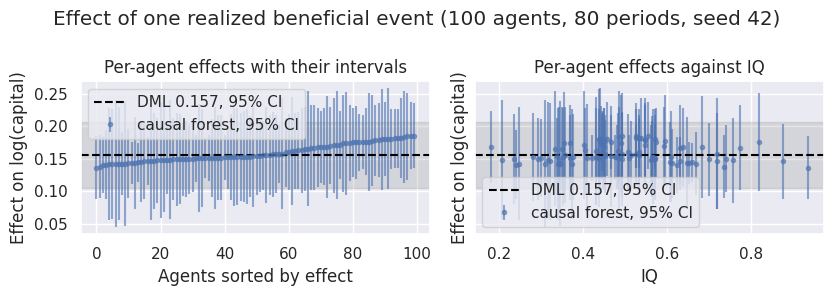

In [24]:
# Plot the per-agent effects with their intervals.
analysis.cell4_5_plot_cate(cate_df, dml_df, setup_txt, figsize=(8.5, 3))

**Guided usage**
- Look at the sorted panel
  - Observe that every interval overlaps the gray DML band
- Look at the IQ panel
  - Observe no clear trend with IQ, given the width of the intervals

**Implementation** `cell4_5_plot_cate(cate_df, dml_df, setup_txt, ...)`
- Draws the precomputed intervals with `matplotlib` `errorbar()`
- Draws the DML effect as a dashed line and its interval as a gray band

In [25]:
hintros.print_obj_info(analysis.cell4_5_plot_cate)

- `cell4_5_plot_cate(cate_df: pandas.DataFrame, dml_df: pandas.DataFrame, setup_txt: str, *, figsize: Optional[Tuple[float, float]] = None) -> None`  
  Plot the per-agent effects with their intervals, sorted and against IQ...

https://github.com/bkk8403/gpsaggese.github.io/blob/UmdTask707_CAASL_Rewrite_example_notebook/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_analysis_utils.py#L623


# Part 5: Resource allocation policies (exploratory)

## Cell 5.1: How the policies run

In [26]:
# Policies of `run_policy_simulation()`, run with `run_experiment()`:
#
# - Each policy adds a budget of 100 to the starting capital, then runs the
#   same simulation with the same seed
#   - `egalitarian`: the same amount to every agent
#   - `meritocratic`: in proportion to the talent norm
#   - `performance`: in proportion to the current capital
#     - Every agent starts with 1.0, so it equals `egalitarian`
#   - `random`: the whole budget to one agent drawn at random
#   - `cate_optimal`: in proportion to the per-agent effects of Cell 4.4
#     - A heuristic, not a proven optimal rule: the effects are of a realized
#       event, not of money
#     - The effects come from the same run that the policy is evaluated on, so
#       the evaluation is in-sample
# - Who is hit by an event does not depend on capital
#   - So every policy run has the same events as the baseline
#   - If the capital floor never binds, agent i ends with C_i0 * M_i, where M_i
#     is the product of the multipliers of its events
#   - A bound floor changes the multiplier of an event with the capital, so
#     this rescaling no longer holds
# - The `sqrt(allocation)` model of the earlier notebook is gone: it was a
#   different experiment, outside the simulator
print("A policy changes the starting capital, not the events of the run")

A policy changes the starting capital, not the events of the run


## Cell 5.2: One run per policy

In [27]:
# Run the baseline config once per policy.
cate_values = cate_df["cate"].to_numpy()
policy_df, policy_results = analysis.cell5_2_run_policy_comparison(
    config, cate_values
)
display(policy_df)
# Outcome: `egalitarian` and `performance` are identical, and `random` has the
# highest total capital (229.4) and Gini (0.690).

,total_initial_capital,total_final_capital,final_to_initial_ratio,mean_capital,median_capital,gini,top_10_pct_share,bottom_50_pct_share
policy,,,,,,,,
none,100.0,88.843462,0.888435,0.888435,0.816072,0.217086,0.184120,0.345020
egalitarian,200.0,177.686924,0.888435,1.776869,1.632143,0.217086,0.184120,0.345020
meritocratic,200.0,177.623729,0.888119,1.776237,1.647219,0.217306,0.185277,0.345290
performance,200.0,177.686924,0.888435,1.776869,1.632143,0.217086,0.184120,0.345020
random,200.0,229.363461,1.146817,2.293635,0.816072,0.690383,0.683971,0.133643
cate_optimal,200.0,177.973059,0.889865,1.779731,1.690076,0.220618,0.185764,0.343582


- The run without allocation (`none`) starts from a total of 100: 100 agents
  with 1.0
- Each funded policy starts from a total of 200: the same 100, plus the budget
  of 100
- The totals are the actual starting capitals: the simulator raises an
  `initial_capital` below the floor to the floor
- `egalitarian` and `performance` give the same row
  - Every agent starts with 2.0 and no agent reaches the floor (Cell 5.3), so
    the Gini stays at 0.217 and the capital keeps 0.888 of its start, as
    without a policy
- `meritocratic` and `cate_optimal` are close to `egalitarian`
  - Their weights vary little across the agents (Cell 5.3)
- `random` gives the whole budget to one agent
  - Its total of 229.4 and Gini of 0.690 depend on how lucky that one agent
    was in this run
- These are single runs with one seed: they do not rank the policies

In [28]:
hintros.print_obj_info(analysis.cell5_2_run_policy_comparison)

- `cell5_2_run_policy_comparison(config: Dict[str, Any], cate_values: numpy.ndarray) -> Tuple[pandas.DataFrame, Dict[str, Dict[str, Any]]]`  
  Run the baseline config once per policy, and summarize each run...

https://github.com/bkk8403/gpsaggese.github.io/blob/UmdTask707_CAASL_Rewrite_example_notebook/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_analysis_utils.py#L718


## Cell 5.3: Policies rescale each agent's luck while the floor never binds

In [29]:
# Infer the starting capital that each policy run implies for each agent.
display(analysis.cell5_3_compute_implied_initial_capital(policy_results))
# Outcome: every run has the same event counts as the baseline and no agent at
# the floor, and the implied starting capital sums to the actual total: 100
# without allocation and 200 for each funded policy.

,same_event_counts,n_agents_at_floor,rescaling_holds,sum_actual_initial,min_implied_initial,mean_implied_initial,max_implied_initial,sum_implied_initial
policy,,,,,,,,
none,True,0,True,100.0,1.000000,1.0,1.000000,100.0
egalitarian,True,0,True,200.0,2.000000,2.0,2.000000,200.0
meritocratic,True,0,True,200.0,1.869592,2.0,2.261779,200.0
performance,True,0,True,200.0,2.000000,2.0,2.000000,200.0
random,True,0,True,200.0,1.000000,2.0,101.000000,200.0
cate_optimal,True,0,True,200.0,1.858125,2.0,2.166703,200.0


- Every policy run keeps the event counts of the baseline
- No agent reaches the capital floor in any run, so `rescaling_holds` is True
- $M_i$ is the final capital over the actual starting capital of the
  baseline
  - The actual one, since an `initial_capital` below the floor starts at the
    floor
- Dividing the final capital by $M_i$ gives back the starting capital of each
  run
  - 1.0 for every agent without allocation (`none`), a total of 100
  - With a funded policy, 1.0 plus the allocation, a total of 200
  - 2.0 for every agent with `egalitarian` and `performance`
  - 1.0 for 99 agents and 101.0 for the winner with `random`
- So in this baseline a policy can only move capital toward agents whose luck
  is already decided by the seed
- With a higher floor, or more or larger unlucky events, the floor can bind
  - Then the helper reports the agents at the floor and does not infer the
    starting capital

In [30]:
hintros.print_obj_info(analysis.cell5_3_compute_implied_initial_capital)

- `cell5_3_compute_implied_initial_capital(policy_results: Dict[str, Dict[str, Any]]) -> pandas.DataFrame`  
  Compute the initial capital that each policy run implies for each agent...

https://github.com/bkk8403/gpsaggese.github.io/blob/UmdTask707_CAASL_Rewrite_example_notebook/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_analysis_utils.py#L819


# Part 6: Comparison with the paper

## Cell 6.1: The baseline over 50 seeds

- The paper reports a Gini averaged over runs, so one seed is not enough to
  compare with it
- This runs the same config with seeds 0 to 49, changing only the seed

In [31]:
# Run the baseline config once per seed.
seeds = list(range(50))
sweep_df = analysis.cell6_1_run_seed_sweep(config, seeds)
display(sweep_df.describe().loc[["mean", "std", "min", "max"]].T)
# Outcome: Gini 0.276 on average, from 0.217 to 0.334, and 2.17 realized
# beneficial events per agent on average.

,mean,std,min,max
talent_std,0.148437,0.006320,0.135617,0.160458
gini,0.275744,0.026878,0.217086,0.333698
top_10_pct_share,0.223974,0.022421,0.184120,0.277983
bottom_50_pct_share,0.311970,0.016515,0.263730,0.350805
mean_lucky_events,2.170400,0.106099,1.970000,2.380000
top_decile_mean_lucky_events,4.712000,0.539705,3.500000,5.800000
r_talent_norm_log_capital,0.125436,0.094189,-0.096479,0.259583
r_lucky_events_log_capital,0.651802,0.065167,0.504022,0.757456
r_net_events_log_capital,0.942430,0.013338,0.911666,0.965812


- Seed 42, the baseline, has the lowest Gini of the 50 seeds: 0.217
- The talent correlation varies a lot with the seed
  - 0.125 on average, with a std of 0.094, from -0.097 to 0.260

## Cell 6.2: The paper's values

In [32]:
# Put the paper's values next to the baseline and the seed average.
comparison_df = analysis.cell6_2_compare_with_paper(
    results,
    sweep_df,
    dml_df["effect"].iloc[0],
    cate_summary_df["std_cate"].iloc[0],
)
display(comparison_df)
# Outcome: Gini 0.38 in the paper, 0.217 for the baseline, and 0.276 over seeds.

,paper,paper_basis,baseline,seeds_mean,seeds_std
metric,,,,,
talent_std,0.110,results section; set-up says 0.15,0.139861,0.148437,0.006320
gini,0.380,"average over runs, number of runs not stated",0.217086,0.275744,0.026878
top_10_pct_share,0.280,not stated,0.184120,0.223974,0.022421
bottom_50_pct_share,0.250,not stated,0.345020,0.311970,0.016515
mean_lucky_events,4.800,not stated,2.320000,2.170400,0.106099
top_decile_mean_lucky_events,8.300,not stated,4.000000,4.712000,0.539705
r_talent_norm_log_capital,0.120,not stated,-0.044716,0.125436,0.094189
r_lucky_events_log_capital,0.780,not stated,0.539700,0.651802,0.065167
r_net_events_log_capital,0.820,not stated,0.919901,0.942430,0.013338


- `baseline` is the single run with seed 42, and `seeds_mean` is the average
  over seeds 0 to 49
- The paper does not say how most of its values were computed: only the Gini
  is stated as an average over runs
- Inequality is lower than in the paper, also on average over seeds
  - Gini 0.276 against 0.38, and no seed above 0.334
  - Top 10% share 22.4% against 28%
- The agents realize fewer beneficial events than in the paper
  - 2.17 per agent on average against 4.8
  - 4.71 in the top decile against 8.3
- The talent correlation is close on average: 0.125 against 0.12
- The event correlations differ in both directions
  - Realized beneficial events: 0.652 against 0.78
  - Net events: 0.942 against 0.82
- The DML effect of the baseline is 0.157 against 0.124, and the CATE std is
  0.013 against 0.03: both are single-seed estimates here
- The parameters were not tuned to match the paper

## Cell 6.3: Seed variability

**Goal**
- See where the baseline and the paper fall in the spread over seeds

**Description**
- Inputs
  - `sweep_df`: the per-seed metrics of Cell 6.1
  - `comparison_df`: the paper and baseline values of Cell 6.2
  - `setup_txt`: the set-up shown in the title

- Panels
  - `Gini of final capital`: histogram over seeds
  - `r(lucky events, log(capital))`: histogram over seeds

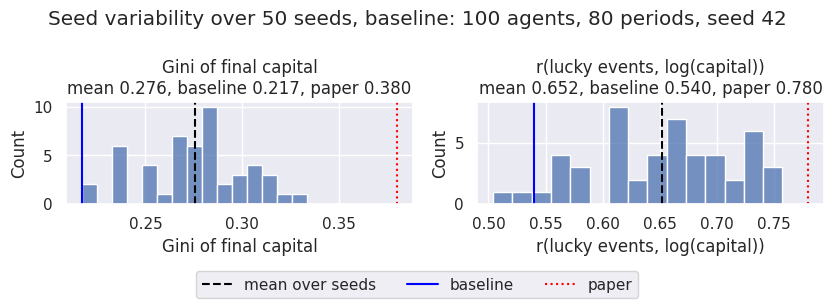

In [33]:
# Plot the spread over seeds with the baseline and the paper.
analysis.cell6_3_plot_seed_sweep(
    sweep_df, comparison_df, setup_txt, figsize=(8.5, 3)
)

**Guided usage**
- Look at the Gini panel
  - Observe the baseline at the left edge and the paper beyond the right edge
- Look at the correlation panel
  - Observe the paper's 0.78 beyond every seed

**Implementation** `cell6_3_plot_seed_sweep(sweep_df, comparison_df, ...)`
- Draws one `seaborn` histogram per metric over the seeds
- Draws the seed mean (dashed), the baseline (solid), and the paper (dotted)

In [34]:
hintros.print_obj_info(analysis.cell6_3_plot_seed_sweep)

- `cell6_3_plot_seed_sweep(sweep_df: pandas.DataFrame, comparison_df: pandas.DataFrame, setup_txt: str, *, figsize: Optional[Tuple[float, float]] = None) -> None`  
  Plot the Gini and the luck correlation over seeds, against the paper...

https://github.com/bkk8403/gpsaggese.github.io/blob/UmdTask707_CAASL_Rewrite_example_notebook/research/Causal_Analysis_of_Agent_Skill_And_Luck/causal_success_analysis_utils.py#L1054


## Cell 6.4: Model differences with the paper

- Spillovers
  - The paper: only a successful lucky event creates a spillover
  - The code: the spillover check runs after every lucky event
  - The notebook describes the code and does not change it
- Talent spread: the paper is not consistent with itself
  - Its simulation set-up draws each talent from $N(0.5, 0.15)$ clipped to
    $[0, 1]$, as the config does
  - Its results report a talent std of 0.11, without saying which measure
  - The simulation gives about 0.148 per talent after clipping (Cell 6.1)
- Performance policy
  - The paper reports different results for `performance` and `egalitarian`
  - The code gives the same result when all agents start with the same
    capital (Cell 5.2)
- Policy totals
  - The paper: total capital 743 without allocation
  - The baseline: 88.8 (Cell 5.2)

# Part 7: Conclusions

## Cell 7.1: What the baseline shows

- With 100 agents and 80 periods, inequality emerges from equal starts
  - Gini 0.217 for seed 42 and 0.276 on average over 50 seeds
  - The median agent ends below its starting capital
- The seed-42 run does not show a statistically distinguishable linear
  association between talent norm and log-capital, while the event counts
  are strongly associated with it
  - Over seeds the talent correlation is 0.125 on average, and varies a lot
- Adjusting for the talents, one more realized beneficial event raises
  log-capital by 0.157 (95% CI [0.106, 0.208])
  - The observed average event-level log gain, 0.199, lies inside the
    interval: consistent with the estimate, but not a validation of it
  - The per-agent effects of the causal forest vary little relative to their
    uncertainty
- While the capital floor never binds, as in the baseline, a policy that
  allocates capital before the run only rescales each agent's luck
  - None of the single runs ranks the policies

## Cell 7.2: Limitations

- Every estimate except the seed sweep comes from one run of 100 agents
- The causal estimates assume that, given the talents, the realized events are
  as good as random
- The CATE-based allocation is a heuristic evaluated in-sample
- A longer run (e.g., 200 periods) is a separate experiment, not part of this
  baseline